In [2]:
import pandas as pd, os, json, numpy as np
p=r'C:\Users\VISHNU\Downloads\Internship\Dataset\Day-6\Data\Netflix_cleaned.csv'
df=pd.read_csv(p)
df.shape, df.columns.tolist(), df.head(3).to_dict('records'), df.dtypes.astype(str).to_dict()


((8790, 10),
 ['show_id',
  'type',
  'title',
  'director',
  'country',
  'date_added',
  'release_year',
  'rating',
  'duration',
  'listed_in'],
 [{'show_id': 's1',
   'type': 'Movie',
   'title': 'Dick Johnson Is Dead',
   'director': 'Kirsten Johnson',
   'country': ',,,U,,,n,,,i,,,t,,,e,,,d,,,S,,,t,,,a,,,t,,,e,,,s,,,',
   'date_added': '9/25/2021',
   'release_year': 2020,
   'rating': 'PG-13',
   'duration': '90 min',
   'listed_in': 'Documentaries'},
  {'show_id': 's3',
   'type': 'Tv Show',
   'title': 'Ganglands',
   'director': 'Julien Leclercq',
   'country': ',,,F,,,r,,,a,,,n,,,c,,,e,,,',
   'date_added': '9/24/2021',
   'release_year': 2021,
   'rating': 'TV-MA',
   'duration': '1 Season',
   'listed_in': 'Crime TV Shows, International TV Shows, TV Action & Adventure'},
  {'show_id': 's6',
   'type': 'Tv Show',
   'title': 'Midnight Mass',
   'director': 'Mike Flanagan',
   'country': ',,,U,,,n,,,i,,,t,,,e,,,d,,,S,,,t,,,a,,,t,,,e,,,s,,,',
   'date_added': '9/24/2021',
 

In [3]:
#inspect nulls, categories and string examples

print("missing", df.isna().sum().to_dict())
print("type",df['type'].value_counts(dropna=False).to_dict())
print("rating", df['rating'].value_counts(dropna=False).head(20).to_dict())
print("durationsamples", df['duration'].value_counts(dropna=False).head(15).to_dict())
print("country raw", df['country'].dropna().head(10).tolist())
print("date parse", pd.to_datetime(df['date_added'], errors='coerce').min(), pd.to_datetime(df['date_added'], errors='coerce').max(), pd.to_datetime(df['date_added'], errors='coerce').isna().sum())


missing {'show_id': 0, 'type': 0, 'title': 0, 'director': 0, 'country': 0, 'date_added': 0, 'release_year': 0, 'rating': 0, 'duration': 0, 'listed_in': 0}
type {'Movie': 6126, 'Tv Show': 2664}
rating {'TV-MA': 3205, 'TV-14': 2157, 'TV-PG': 861, 'R': 799, 'PG-13': 490, 'TV-Y7': 333, 'TV-Y': 306, 'PG': 287, 'TV-G': 220, 'NR': 79, 'G': 41, 'TV-Y7-FV': 6, 'NC-17': 3, 'UR': 3}
durationsamples {'1 Season': 1791, '2 Seasons': 421, '3 Seasons': 198, '90 min': 152, '97 min': 146, '94 min': 146, '93 min': 146, '91 min': 144, '95 min': 137, '96 min': 130, '92 min': 129, '102 min': 122, '98 min': 120, '99 min': 118, '88 min': 116}
country raw [',,,U,,,n,,,i,,,t,,,e,,,d,,,S,,,t,,,a,,,t,,,e,,,s,,,', ',,,F,,,r,,,a,,,n,,,c,,,e,,,', ',,,U,,,n,,,i,,,t,,,e,,,d,,,S,,,t,,,a,,,t,,,e,,,s,,,', ',,,B,,,r,,,a,,,z,,,i,,,l,,,', ',,,U,,,n,,,i,,,t,,,e,,,d,,,S,,,t,,,a,,,t,,,e,,,s,,,', ',,,U,,,n,,,i,,,t,,,e,,,d,,,K,,,i,,,n,,,g,,,d,,,o,,,m,,,', ',,,U,,,n,,,i,,,t,,,e,,,d,,,S,,,t,,,a,,,t,,,e,,,s,,,', ',,,I,,,n,,,d,,,i,,

In [4]:
d=df.copy()
d['country_clean']=d['country'].str.replace(',','',regex=False).str.strip()
d['date_added_clean']=pd.to_datetime(d['date_added'], format='mixed', errors='coerce')
d['duration_num']=pd.to_numeric(d['duration'].str.extract(r'(\d+)')[0], errors='coerce')
d['duration_unit']=d['duration'].str.extract(r'([A-Za-z]+)')[0]
print("dates", d.date_added_clean.notna().sum(), d.date_added_clean.min(), d.date_added_clean.max())
print("country top", d.country_clean.value_counts().head(15).to_dict())
print("year top", d.release_year.value_counts().head(10).to_dict())
print("date added year", d.date_added_clean.dt.year.value_counts().sort_index().to_dict())
print("type split", d.groupby('type').size().to_dict())
print("avg duration", d.groupby('type').duration_num.agg(['count','mean','median']).to_dict())
print("movies avg runtime", d.loc[d.type.eq('Movie'),'duration_num'].mean())
print("tv seasons",d.loc[d.type.eq('Tv Show'),'duration_num'].mean())
print("genres", d.listed_in.str.split(', ').explode().value_counts().head(20).to_dict())
print("directors", d.director.value_counts().head(15).to_dict())
print("ratings", d.rating.value_counts().to_dict())
print("country blankish", d.country_clean.eq('').sum())


dates 8790 2008-01-01 00:00:00 2021-09-25 00:00:00
country top {'UnitedStates': 3240, 'India': 1057, 'UnitedKingdom': 638, 'Pakistan': 421, 'NotGiven': 287, 'Canada': 271, 'Japan': 259, 'SouthKorea': 214, 'France': 213, 'Spain': 182, 'Mexico': 138, 'Egypt': 123, 'Australia': 114, 'Turkey': 112, 'Nigeria': 105}
year top {2018: 1146, 2019: 1030, 2017: 1030, 2020: 953, 2016: 901, 2021: 592, 2015: 555, 2014: 352, 2013: 286, 2012: 236}
date added year {2008: 2, 2009: 2, 2010: 1, 2011: 13, 2012: 3, 2013: 11, 2014: 24, 2015: 82, 2016: 426, 2017: 1185, 2018: 1648, 2019: 2016, 2020: 1879, 2021: 1498}
type split {'Movie': 6126, 'Tv Show': 2664}
avg duration {'count': {'Movie': 6126, 'Tv Show': 2664}, 'mean': {'Movie': 99.58488410055502, 'Tv Show': 1.7518768768768769}, 'median': {'Movie': 98.0, 'Tv Show': 1.0}}
movies avg runtime 99.58488410055502
tv seasons 1.7518768768768769
genres {'International Movies': 2752, 'Dramas': 2426, 'Comedies': 1674, 'International TV Shows': 1349, 'Documentaries': 

In [5]:
# summary numbers
n=len(d)
print("movie pct",round((d.type.eq('Movie').mean()*100),2),"tv pct",round((d.type.eq('Tv Show').mean()*100),2))
print("date_added latest year top",d.date_added_clean.dt.year.value_counts().head(5).to_dict())
print("release range",d.release_year.min(),d.release_year.max())
print("post 2015", (d.release_year>=2015).sum(), round((d.release_year>=2015).mean()*100,1))
print("country counts top 10", d.country_clean.value_counts().head(10))
print("unknown director", (d.director.str.strip().str.lower().isin(['not given','not available','unknown',''])).sum())
print("unknown country", d.country_clean.str.lower().isin(['notgiven','not given','unknown','']).sum())
print("genre count total exploded",len(d.listed_in.str.split(', ').explode()))
print("unique genres",d.listed_in.str.split(', ').explode().nunique())
print("top added months",d.date_added_clean.dt.month_name().value_counts().head(12).to_dict())
print("type rating top",d.groupby(['type','rating']).size().sort_values(ascending=False).head(12).to_dict())
print("movie durations quartiles",d.loc[d.type.eq('Movie'),'duration_num'].describe().round(1).to_dict())
print("TV season distribution",d.loc[d.type.eq('Tv Show'),'duration_num'].value_counts().head(10).to_dict())


movie pct 69.69 tv pct 30.31
date_added latest year top {2019: 2016, 2020: 1879, 2018: 1648, 2021: 1498, 2017: 1185}
release range 1925 2021
post 2015 6207 70.6
country counts top 10 country_clean
UnitedStates     3240
India            1057
UnitedKingdom     638
Pakistan          421
NotGiven          287
Canada            271
Japan             259
SouthKorea        214
France            213
Spain             182
Name: count, dtype: int64
unknown director 2588
unknown country 287
genre count total exploded 19294
unique genres 42
top added months {'July': 827, 'December': 812, 'September': 769, 'April': 763, 'October': 760, 'August': 754, 'March': 741, 'January': 737, 'June': 728, 'November': 705, 'May': 632, 'February': 562}
type rating top {('Movie', 'TV-MA'): 2062, ('Movie', 'TV-14'): 1427, ('Tv Show', 'TV-MA'): 1143, ('Movie', 'R'): 797, ('Tv Show', 'TV-14'): 730, ('Movie', 'TV-PG'): 540, ('Movie', 'PG-13'): 490, ('Tv Show', 'TV-PG'): 321, ('Movie', 'PG'): 287, ('Tv Show', 'TV-Y7'):

In [6]:
# output exact top categories and rates
for name, series in [
    ("genres",d['listed_in'].str.split(', ').explode().value_counts().head(10)),
    ("countries",d['country_clean'].str.replace(r'(?<=[a-z])(?=[A-Z])',' ',regex=True).value_counts().head(10)),
    ("release_years",d['release_year'].value_counts().head(10)),
    ("ratings",d['rating'].value_counts().head(10)),
]:
    print("\n",name)
    print(series.to_string())
print("top rating pct",3205/n*100, "TVMA")
print("2019 additions pct",2016/n*100)
print("year 2018 release count",1146)
print("director missing pct",2588/n*100,"country unknown",287/n*100)



 genres
listed_in
International Movies        2752
Dramas                      2426
Comedies                    1674
International TV Shows      1349
Documentaries                869
Action & Adventure           859
TV Dramas                    762
Independent Movies           756
Children & Family Movies     641
Romantic Movies              616

 countries
country_clean
United States     3240
India             1057
United Kingdom     638
Pakistan           421
Not Given          287
Canada             271
Japan              259
South Korea        214
France             213
Spain              182

 release_years
release_year
2018    1146
2019    1030
2017    1030
2020     953
2016     901
2021     592
2015     555
2014     352
2013     286
2012     236

 ratings
rating
TV-MA    3205
TV-14    2157
TV-PG     861
R         799
PG-13     490
TV-Y7     333
TV-Y      306
PG        287
TV-G      220
NR         79
top rating pct 36.46188850967008 TVMA
2019 additions pct 22.935153583617748
yea

In [7]:
# Step 1: Import libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings("ignore")

# Step 2: Load dataset

df = pd.read_csv(r"C:\Users\VISHNU\Downloads\Internship\Dataset\Day-6\Data\Netflix_cleaned.csv")

# Display first five records
display(df.head())

# Dataset dimensions
print("Dataset Shape:", df.shape)

# Column names
print("Columns:", df.columns.tolist())

# Dataset information
df.info()

,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,",,,U,,,n,,,i,,,t,,,e,,,d,,,S,,,t,,,a,,,t,,,e,,...",9/25/2021,2020,PG-13,90 min,Documentaries
1,s3,Tv Show,Ganglands,Julien Leclercq,",,,F,,,r,,,a,,,n,,,c,,,e,,,",9/24/2021,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act..."
2,s6,Tv Show,Midnight Mass,Mike Flanagan,",,,U,,,n,,,i,,,t,,,e,,,d,,,S,,,t,,,a,,,t,,,e,,...",9/24/2021,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries"
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,",,,B,,,r,,,a,,,z,,,i,,,l,,,",9/22/2021,2021,TV-PG,91 min,"Children & Family Movies, Comedies"
4,s8,Movie,Sankofa,Haile Gerima,",,,U,,,n,,,i,,,t,,,e,,,d,,,S,,,t,,,a,,,t,,,e,,...",9/24/2021,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies"


Dataset Shape: (8790, 10)
Columns: ['show_id', 'type', 'title', 'director', 'country', 'date_added', 'release_year', 'rating', 'duration', 'listed_in']
<class 'pandas.DataFrame'>
RangeIndex: 8790 entries, 0 to 8789
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   show_id       8790 non-null   str  
 1   type          8790 non-null   str  
 2   title         8790 non-null   str  
 3   director      8790 non-null   str  
 4   country       8790 non-null   str  
 5   date_added    8790 non-null   str  
 6   release_year  8790 non-null   int64
 7   rating        8790 non-null   str  
 8   duration      8790 non-null   str  
 9   listed_in     8790 non-null   str  
dtypes: int64(1), str(9)
memory usage: 1.8 MB


In [8]:
# Missing values
print(df.isnull().sum())

# Missing value percentage
missing = (
    df.isnull().sum() / len(df) * 100
).round(2)

print(missing)

show_id         0
type            0
title           0
director        0
country         0
date_added      0
release_year    0
rating          0
duration        0
listed_in       0
dtype: int64
show_id         0.0
type            0.0
title           0.0
director        0.0
country         0.0
date_added      0.0
release_year    0.0
rating          0.0
duration        0.0
listed_in       0.0
dtype: float64


In [10]:
#Remove Duplicate
print("Duplicate:",df.duplicated().sum())

df=df.drop_duplicates()

print("Shape after removing duplicates:", df.shape)

Duplicate: 0
Shape after removing duplicates: (8790, 10)


In [11]:
#Correct country name

# Remove unwanted commas
df["country"] = (
    df["country"]
    .astype(str)
    .str.replace(",", "", regex=False)
    .str.strip()
)

# Improve country formatting
df["country"] = df["country"].str.replace(
    r"(?<=[a-z])(?=[A-Z])",
    " ",
    regex=True
)

# Standardize missing placeholders
df["country"] = df["country"].replace(
    ["NotGiven", "Not Given", "nan", ""],
    np.nan
)


In [12]:
#Handle missing director values

df["director"] = df["director"].replace(
    ["not Given", "Not Available", "Unknown", ""],
    np.nan
)

df["director"] = df["director"].fillna("Unknown")

In [13]:
#Convert date column
df["date_added"]=pd.to_datetime(
    df["date_added"],
    format="mixed",
    errors="coerce"
)

df["added_year"] = df["date_added"].dt.year

df["added_month"] = df["date_added"].dt.month_name()

In [15]:
#Extract duration
df["duration_value"] = pd.to_numeric(
    df["duration"].str.extract(r"(\d+)")[0],
    errors="coerce"
)

df["duration_unit"] = df["duration"].str.extract(
    r"([A-Za-z]+)"
)[0]

In [16]:
#Final cleaning check

print("final Shape:",df.shape)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nMissing Records:")
print(df.duplicated().sum())

display(df.head())

final Shape: (8790, 14)

Missing Values:
show_id             0
type                0
title               0
director            0
country           287
date_added          0
release_year        0
rating              0
duration            0
listed_in           0
added_year          0
added_month         0
duration_value      0
duration_unit       0
dtype: int64

Missing Records:
0


,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in,added_year,added_month,duration_value,duration_unit
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,2021-09-25,2020,PG-13,90 min,Documentaries,2021,September,90,min
1,s3,Tv Show,Ganglands,Julien Leclercq,France,2021-09-24,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",2021,September,1,Season
2,s6,Tv Show,Midnight Mass,Mike Flanagan,United States,2021-09-24,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries",2021,September,1,Season
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,2021-09-22,2021,TV-PG,91 min,"Children & Family Movies, Comedies",2021,September,91,min
4,s8,Movie,Sankofa,Haile Gerima,United States,2021-09-24,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies",2021,September,125,min


In [17]:
#Save the cleaned dataset:
df.to_csv(
    "Netflix_Final_Cleaned.csv",
    index=False
)

type
Movie      6126
Tv Show    2664
Name: count, dtype: int64


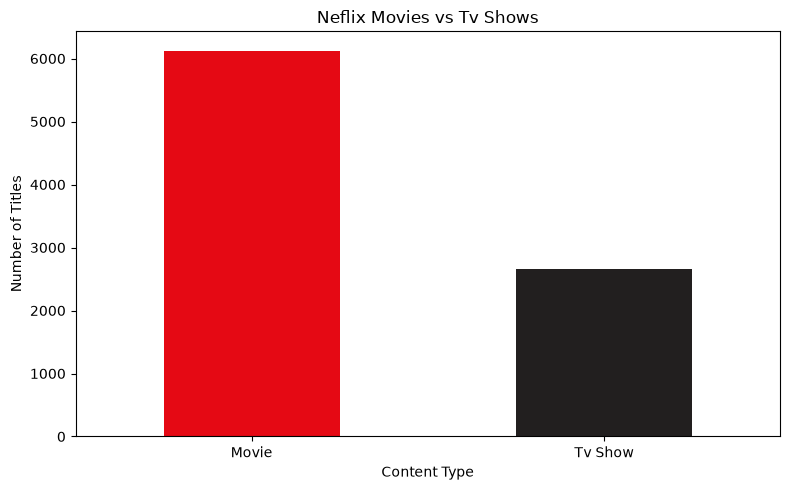

In [19]:
#Step 3 – Exploratory Data Analysis (EDA)
content_type = df["type"].value_counts()

print(content_type)

plt.figure(figsize=(8,5))

content_type.plot(
    kind="bar",
    color=["#E50914", "#221F1F"]
)

plt.title("Neflix Movies vs Tv Shows")
plt.xlabel("Content Type")
plt.ylabel("Number of Titles")

plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

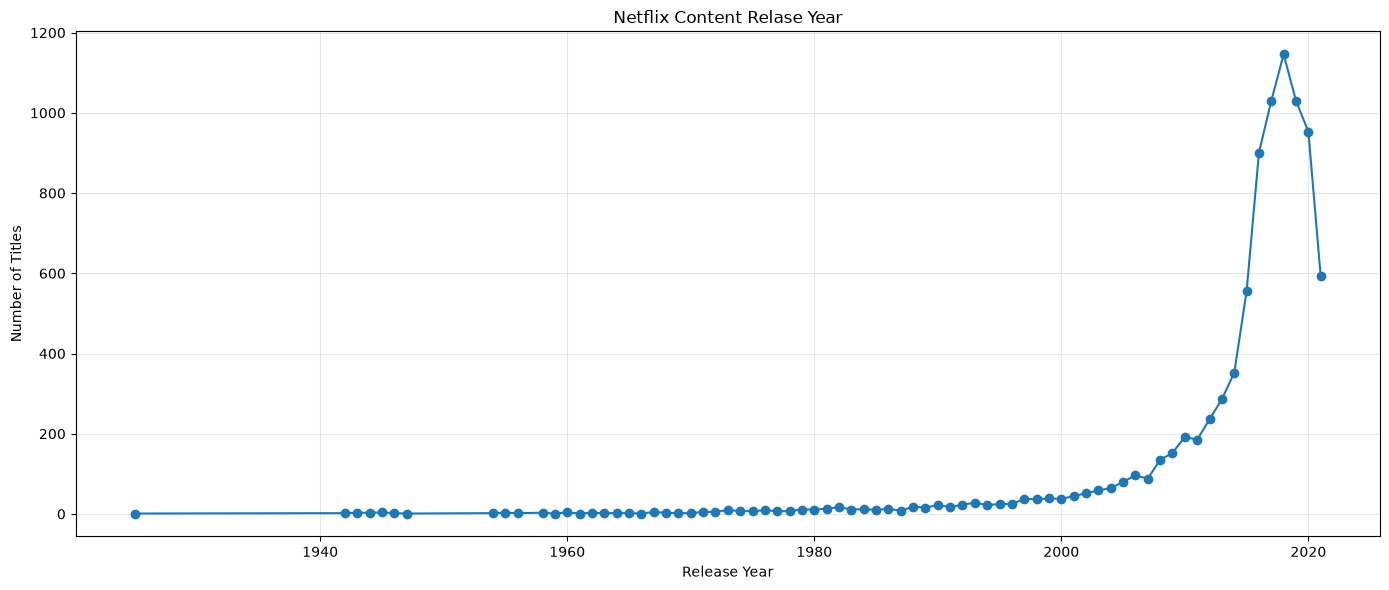

In [22]:
#Content distribution by release year

release_trend = df["release_year"].value_counts().sort_index()

plt.figure(figsize=(14, 6))
plt.plot(
    release_trend.index,
    release_trend.values,
    marker="o"
)

plt.title("Netflix Content Relase Year")
plt.xlabel("Release Year")
plt.ylabel("Number of Titles")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

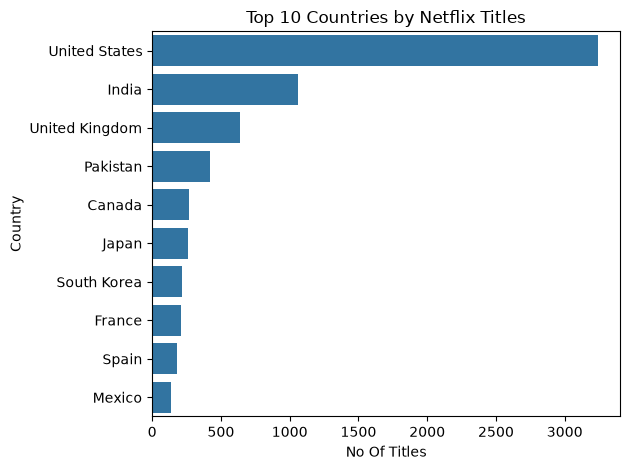

In [23]:
#Top 10 countries

top_countries = (
    df["country"]
    .dropna()
    .value_counts()
    .head(10)
)

plt.Figure(figsize=(12, 6))
sns.barplot(
    x=top_countries.values,
    y=top_countries.index
)

plt.title("Top 10 Countries by Netflix Titles")
plt.xlabel("No Of Titles")
plt.ylabel("Country")

plt.tight_layout()
plt.show()

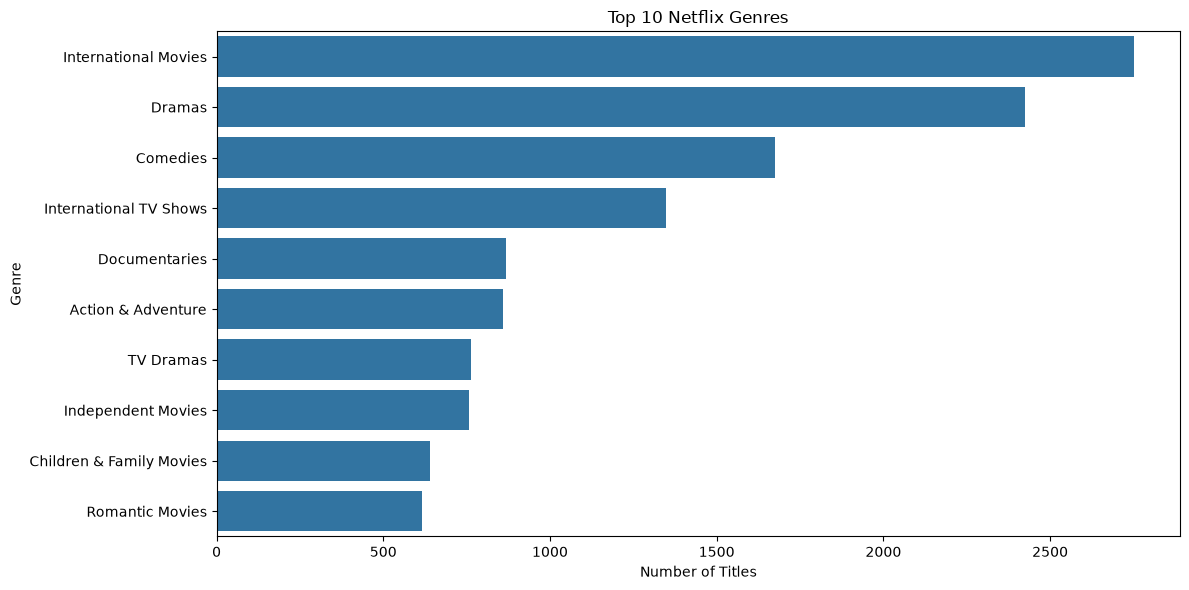

In [24]:
#Top 10 genres
genres = (
    df["listed_in"]
    .dropna()
    .str.split(", ")
    .explode()
)

top_genres = genres.value_counts().head(10)

plt.figure(figsize=(12, 6))

sns.barplot(
    x=top_genres.values,
    y=top_genres.index
)

plt.title("Top 10 Netflix Genres")
plt.xlabel("Number of Titles")
plt.ylabel("Genre")

plt.tight_layout()
plt.show()

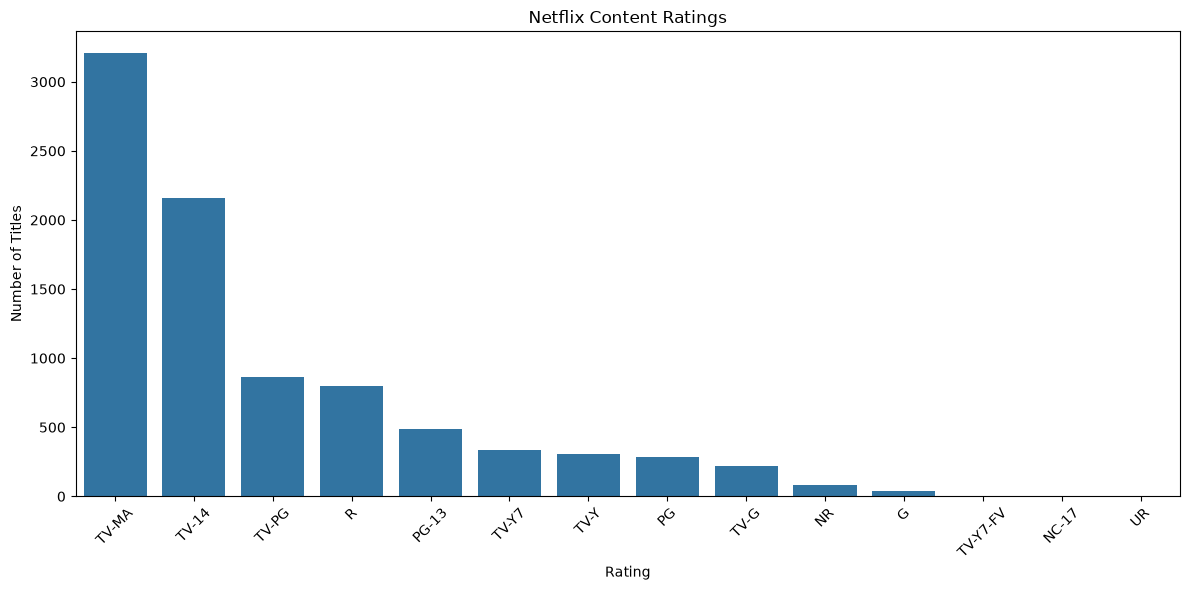

In [25]:
#Content rating distribution
rating_counts = df["rating"].value_counts()

plt.figure(figsize=(12, 6))

sns.barplot(
    x=rating_counts.index,
    y=rating_counts.values
)

plt.title("Netflix Content Ratings")
plt.xlabel("Rating")
plt.ylabel("Number of Titles")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

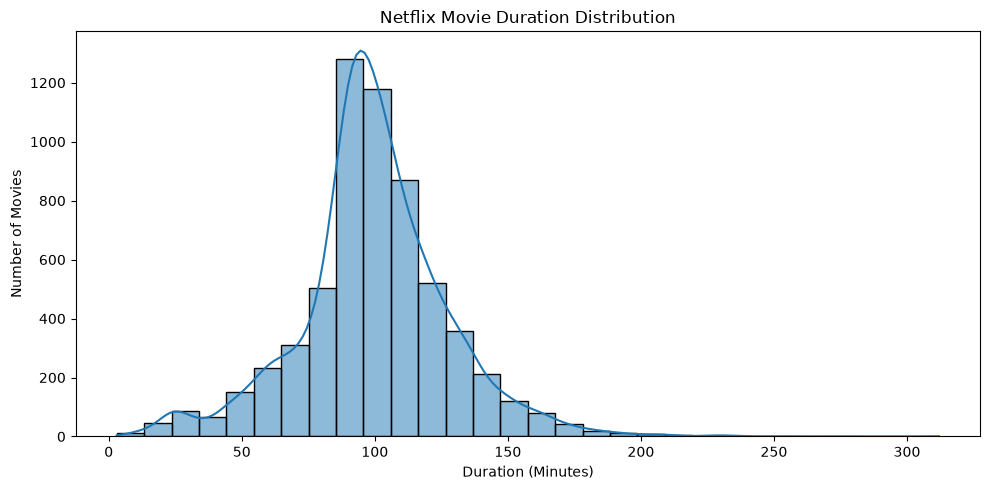

In [26]:
#Movie duration analysis
movies = df[df["type"] == "Movie"].copy()

plt.figure(figsize=(10, 5))

sns.histplot(
    movies["duration_value"].dropna(),
    bins=30,
    kde=True
)

plt.title("Netflix Movie Duration Distribution")
plt.xlabel("Duration (Minutes)")
plt.ylabel("Number of Movies")

plt.tight_layout()
plt.show()

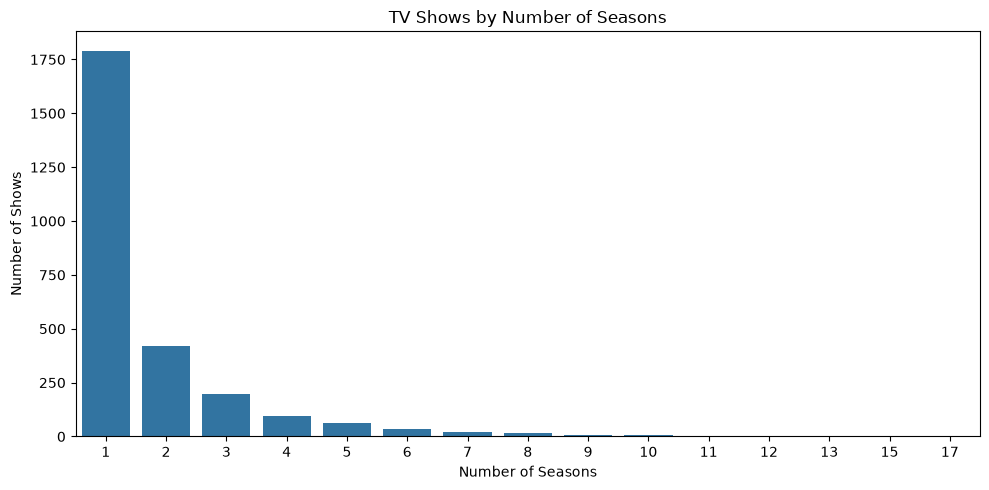

In [27]:
#TV Show season analysis
tv_shows = df[df["type"] == "Tv Show"].copy()

season_counts = tv_shows["duration_value"].value_counts().sort_index()

plt.figure(figsize=(10, 5))

sns.barplot(
    x=season_counts.index,
    y=season_counts.values
)

plt.title("TV Shows by Number of Seasons")
plt.xlabel("Number of Seasons")
plt.ylabel("Number of Shows")

plt.tight_layout()
plt.show()